Personal Parameters (Section 0.1)

In [1]:
SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print("SID4 :", SID4)
print("SEED :", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)

import random, numpy as np
random.seed(SEED)
np.random.seed(SEED)

SID4 : 2733
SEED : 2733
SLICE: 733
HP_ID: 3
CLS_A: 3
CLS_B: 7


1. Perform embedding-based transfer learning on a text dataset (Dataset: IMDB Movie Reviews). (4 points)

* Load a pretrained Word2Vec model (word2vec-google-news-300).
* For the words cast, score, plot, screen, review, extract the top-3 nearest neighbors and cosine similarity scores.

In [2]:
!pip install -q gensim

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import gensim.downloader as api
from gensim.models import Word2Vec

TARGET_WORDS = ['cast', 'score', 'plot', 'screen', 'review']

wv_pretrained = api.load('word2vec-google-news-300')
pretrained_path = api.load('word2vec-google-news-300', return_path=True)

print(wv_pretrained['movie'].shape)

def top3_neighbors(model, word):
    return model.most_similar(word, topn=3)

pretrained_results = {w: top3_neighbors(wv_pretrained, w) for w in TARGET_WORDS}
for w, neighbors in pretrained_results.items():
    print(w, '->', neighbors)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 53.2 MB/s eta 0:00:00
[==================================================] 100.0% 1662.8/1662.8MB downloaded
(300,)
cast -> [('casts', 0.72188800573349), ('casting', 0.7188456058502197), ('Cast', 0.6638122200965881)]
score -> [('scoring', 0.71968013048172), ('scores', 0.659572422504425), ('scored', 0.6384159326553345)]
plot -> [('plots', 0.7624845504760742), ('Plot', 0.6524182558059692), ('plotting', 0.6327632069587708)]
screen -> [('screens', 0.7728806734085083), ('onscreen', 0.6115447282791138), ('LCD_screen', 0.5599321126937866)]
review -> [('reviewed', 0.6630409359931946), ('reviewing', 0.6609557271003723), ('reviews', 0.6379557251930237)]


Load IMDB review text

In [3]:
import pandas as pd

IMDB_CSV_URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
imdb_df = pd.read_csv(IMDB_CSV_URL)
raw_texts_all = imdb_df['review'].tolist()
print("full IMDB dataset size:", len(raw_texts_all))

N_SUBSET = 8000
start = SLICE  # Sec 0.1: SLICE = start index of your dataset subset
end = start + N_SUBSET
if end > len(raw_texts_all):
    raw_texts = raw_texts_all[start:] + raw_texts_all[:end - len(raw_texts_all)]
else:
    raw_texts = raw_texts_all[start:end]

def tokenize(text):
    text = re.sub(r'<br\s*/?>', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return text.lower().split()

tokenized_sentences = [tokenize(t) for t in raw_texts]
print(len(tokenized_sentences), "reviews in subset (SLICE =", SLICE, ")")
print(tokenized_sentences[0][:20])

full IMDB dataset size: 50000
8000 reviews in subset (SLICE = 733 )
['that', 's', 'how', 'burt', 'reynolds', 'describes', 'this', 'film', 'which', 'happens', 'to', 'be', 'his', 'best', 'ever', 'he', 'plays', 'tom', 'sharky', 'a']


Fine-tune the pretrained embeddings on the IMDB review text

In [4]:
model = Word2Vec(vector_size=300, window=5, min_count=2, workers=4, sg=1, epochs=5, seed=SEED)
model.build_vocab(tokenized_sentences)

model.wv.vectors_lockf = np.ones(len(model.wv))
model.wv.intersect_word2vec_format(pretrained_path, binary=True, lockf=1.0)

model.train(tokenized_sentences, total_examples=model.corpus_count, epochs=model.epochs)
wv_finetuned = model.wv

print("fine-tuned vocab size:", len(wv_finetuned))

fine-tuned vocab size: 28780


 Re-extract top-3 nearest neighbors after fine-tuning, and compare in a table

In [5]:
finetuned_results = {w: top3_neighbors(wv_finetuned, w) for w in TARGET_WORDS}

for w, neighbors in finetuned_results.items():
    print(w, '->', neighbors)

rows = []
for w in TARGET_WORDS:
    rows.append({
        'word': w,
        'pretrained_top3': pretrained_results[w],
        'finetuned_top3': finetuned_results[w],
    })

comparison_df = pd.DataFrame(rows)
comparison_df

cast -> [('casts', 0.72188800573349), ('casting', 0.7188456058502197), ('casted', 0.6500102281570435)]
score -> [('scoring', 0.71968013048172), ('scored', 0.6384159326553345), ('scores', 0.5610866546630859)]
plot -> [('plots', 0.48393768072128296), ('plotline', 0.47740739583969116), ('twists', 0.47605806589126587)]
screen -> [('screens', 0.6864439845085144), ('onscreen', 0.6115447282791138), ('widescreen', 0.5402124524116516)]
review -> [('reviews', 0.4756574332714081), ('evaluation', 0.4377292990684509), ('filmcritic', 0.4376426339149475)]


,word,pretrained_top3,finetuned_top3
0,cast,"[(casts, 0.72188800573349), (casting, 0.718845...","[(casts, 0.72188800573349), (casting, 0.718845..."
1,score,"[(scoring, 0.71968013048172), (scores, 0.65957...","[(scoring, 0.71968013048172), (scored, 0.63841..."
2,plot,"[(plots, 0.7624845504760742), (Plot, 0.6524182...","[(plots, 0.48393768072128296), (plotline, 0.47..."
3,screen,"[(screens, 0.7728806734085083), (onscreen, 0.6...","[(screens, 0.6864439845085144), (onscreen, 0.6..."
4,review,"[(reviewed, 0.6630409359931946), (reviewing, 0...","[(reviews, 0.4756574332714081), (evaluation, 0..."


Cosine similarity between original and fine-tuned vectors — which word shifted most/least

In [6]:
def cosine_sim(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

shift_rows = []
for w in TARGET_WORDS:
    sim = cosine_sim(wv_pretrained[w], wv_finetuned[w])
    shift_rows.append({'word': w, 'cosine_sim_old_vs_new': sim})

shift_df = pd.DataFrame(shift_rows).sort_values('cosine_sim_old_vs_new')
print(shift_df)
print("Most shifted (lowest similarity):", shift_df.iloc[0]['word'])
print("Least shifted (highest similarity):", shift_df.iloc[-1]['word'])

     word  cosine_sim_old_vs_new
4  review               0.497912
2    plot               0.640529
3  screen               1.000000
1   score               1.000000
0    cast               1.000000
Most shifted (lowest similarity): review
Least shifted (highest similarity): cast


Visualize the embedding shift in 2D (t-SNE) for one word

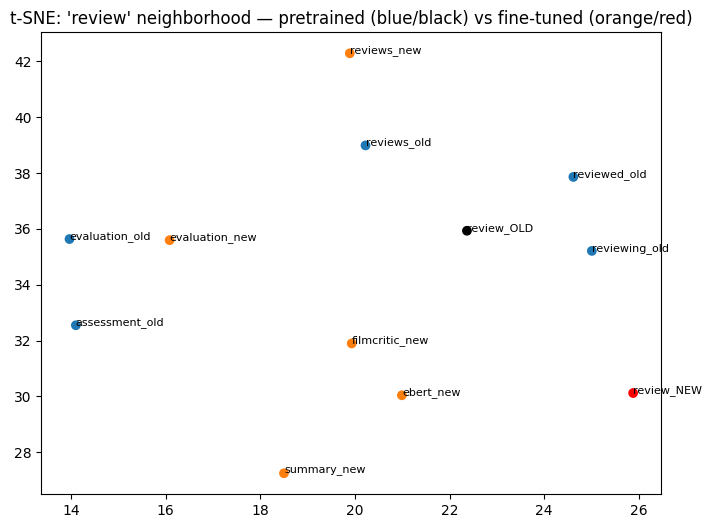

In [7]:
def plot_shift(word, wv_old, wv_new, k=5):
    old_neighbors = [n for n, _ in wv_old.most_similar(word, topn=k)]
    new_neighbors = [n for n, _ in wv_new.most_similar(word, topn=k)]

    labels, vectors, colors = [], [], []
    for n in old_neighbors:
        labels.append(n + '_old'); vectors.append(wv_old[n]); colors.append('tab:blue')
    for n in new_neighbors:
        labels.append(n + '_new'); vectors.append(wv_new[n]); colors.append('tab:orange')
    labels.append(word + '_OLD'); vectors.append(wv_old[word]); colors.append('black')
    labels.append(word + '_NEW'); vectors.append(wv_new[word]); colors.append('red')

    vectors = np.array(vectors)
    coords = TSNE(n_components=2, perplexity=5, random_state=SEED).fit_transform(vectors)

    plt.figure(figsize=(8, 6))
    plt.scatter(coords[:, 0], coords[:, 1], c=colors)
    for label, (x, y) in zip(labels, coords):
        plt.annotate(label, (x, y), fontsize=8)
    plt.title(f"t-SNE: '{word}' neighborhood — pretrained (blue/black) vs fine-tuned (orange/red)")
    plt.show()

plot_shift('review', wv_pretrained, wv_finetuned)

2. Build a Retrieval-Augmented Generation (RAG) pipeline using LangChain (Dataset: Wikipedia pages for 10 movies).

 Load the 10 documents using a LangChain Document Loader.

In [8]:
!pip install -q langchain langchain-core requests

import requests
from langchain_core.documents import Document
from langchain_core.document_loaders import BaseLoader

class SimpleWikipediaLoader(BaseLoader):
    """A LangChain Document Loader that pulls a Wikipedia article's plain-text
    extract via the MediaWiki API (redirects=1 so titles like 'Jurassic Park
    (film)' resolve correctly instead of returning an empty page)."""

    def __init__(self, title):
        self.title = title

    def load(self):
        url = "https://en.wikipedia.org/w/api.php"
        params = {"action": "query", "prop": "extracts", "explaintext": True,
                  "titles": self.title, "redirects": 1, "format": "json"}
        headers = {"User-Agent": "SJSU-DATA266-HW/1.0 (student assignment; contact: sadaffatima.syeda@sjsu.edu)"}
        resp = requests.get(url, params=params, headers=headers, timeout=15)
        resp.raise_for_status()
        pages = resp.json()["query"]["pages"]
        page = next(iter(pages.values()))
        text = page.get("extract", "")
        return [Document(
            page_content=text,
            metadata={"title": page.get("title", self.title),
                      "source": f"https://en.wikipedia.org/wiki/{self.title.replace(' ', '_')}"}
        )]

MOVIES = [
    "Inception", "The Matrix", "Titanic (1997 film)", "The Godfather",
    "Parasite (2019 film)", "Interstellar (film)", "The Dark Knight",
    "Pulp Fiction", "Forrest Gump", "Jurassic Park (film)",
]

documents = []
for title in MOVIES:
    documents.extend(SimpleWikipediaLoader(title).load())

print(len(documents), "documents loaded")
for d in documents:
    print(d.metadata['title'], '-', len(d.page_content), 'characters')

10 documents loaded
Inception - 52430 characters
The Matrix - 61192 characters
Titanic (1997 film) - 89379 characters
The Godfather - 55086 characters
Parasite (2019 film) - 39438 characters
Interstellar (film) - 45293 characters
The Dark Knight - 73031 characters
Pulp Fiction - 81910 characters
Forrest Gump - 36744 characters
Jurassic Park - 105601 characters


Split the documents into chunks (chunk size 500, overlap 50)

In [9]:
!pip install -q langchain-text-splitters

from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(documents)

print(len(chunks), "chunks created from", len(documents), "documents")
print(chunks[0].page_content[:200])
print(chunks[0].metadata)

1925 chunks created from 10 documents
Inception is a 2010  science fiction action film written and directed by Christopher Nolan, who also produced it with Emma Thomas, his wife. The film stars Leonardo DiCaprio as a professional thief wh
{'title': 'Inception', 'source': 'https://en.wikipedia.org/wiki/Inception'}


Generate embeddings for the chunks and store them in a Vector Store

In [11]:
!pip install -q langchain-huggingface sentence-transformers faiss-cpu langchain-community

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

embedding_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vector_store = FAISS.from_documents(chunks, embedding_model)

print("Vector store built with", vector_store.index.ntotal, "vectors")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/tmp/ipykernel_4840/3074370546.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Vector store built with 1925 vectors


Build the pipeline using explicit components (Prompt Template, retriever, LLM)

In [12]:
!pip install -q transformers accelerate

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from langchain_core.prompts import PromptTemplate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("LLM running on:", device)

doc_retriever = vector_store.as_retriever(search_kwargs={"k": 3})

tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")
seq2seq_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(device)

class LocalSeq2SeqLLM:
    def invoke(self, prompt, max_new_tokens=150):
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(device)
        with torch.no_grad():
            output_ids = seq2seq_model.generate(**inputs, max_new_tokens=max_new_tokens)
        return tokenizer.decode(output_ids[0], skip_special_tokens=True)

local_llm = LocalSeq2SeqLLM()

qa_prompt = PromptTemplate(
    input_variables=["context", "question"],
    template=(
        "Use ONLY the context below to answer the question. "
        "If the context doesn't contain the answer, say you don't know.\n\n"
        "Context:\n{context}\n\n"
        "Question: {question}\n"
        "Answer:"
    ),
)

def run_rag_query(user_question, top_k=3):
    top_chunks = doc_retriever.invoke(user_question)[:top_k]
    combined_context = "\n\n".join(chunk.page_content for chunk in top_chunks)
    filled_prompt = qa_prompt.format(context=combined_context, question=user_question)
    generated_answer = local_llm.invoke(filled_prompt)
    return generated_answer, top_chunks

def show_result(question):
    generated_answer, top_chunks = run_rag_query(question)
    print(f">>> {question}")
    print(f"{generated_answer}\n")
    for i, chunk in enumerate(top_chunks, 1):
        print(f"[{i}] {chunk.metadata['title']} :: {chunk.page_content[:100]}")
    return generated_answer, top_chunks

_ = show_result("What is the plot of The Matrix about?")

LLM running on: cpu


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

>>> What is the plot of The Matrix about?
a dystopian future in which humanity is unknowingly trapped inside the Matrix

[1] The Matrix :: === Awards and nominations ===


== Thematic analysis ==

The Matrix draws from and alludes to numer
[2] Inception :: characters navigate it. By contrast, the world of The Matrix (1999) is an authoritarian, computer-co
[3] The Matrix :: The Matrix is a 1999 science fiction action film written and directed by the Wachowskis. The first i


Write 5 questions answerable from the documents and run each through the retriever + LLM

In [13]:
QUESTIONS = [
    "Who directed Inception?",
    "In what year was The Matrix released?",
    "Who directed The Godfather?",
    "What is Parasite about?",
    "Who composed the musical score for Jurassic Park?",
]

qa_results = []
for q in QUESTIONS:
    answer, chunks = show_result(q)
    qa_results.append({"question": q, "answer": answer, "chunks": chunks})
    print("-" * 80)

>>> Who directed Inception?
Christopher Nolan

[1] Inception :: Inception is a 2010  science fiction action film written and directed by Christopher Nolan, who also
[2] Inception :: person, to try to articulate some of the things that have been swirling around his head for the last
[3] Inception :: Inception's premiere was held in London on July 8, 2010; it was released in both conventional and IM
--------------------------------------------------------------------------------
>>> In what year was The Matrix released?
1999

[1] The Matrix :: The Matrix is considered to be among the greatest science fiction films of all time. In 2012, it was
[2] The Matrix :: The Matrix is a 1999 science fiction action film written and directed by the Wachowskis. The first i
[3] The Matrix :: along with the two sequels as The Complete Matrix Trilogy. It was also released on 4K HDR Blu-ray on
--------------------------------------------------------------------------------
>>> Who directed The Godfather?


 Change the chunk size or overlap for 2 of the 5 questions, re-run, and compare

In [14]:
splitter_v2 = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
chunks_v2 = splitter_v2.split_documents(documents)
vector_store_v2 = FAISS.from_documents(chunks_v2, embedding_model)
retriever_v2 = vector_store_v2.as_retriever(search_kwargs={"k": 3})

def run_rag_query_v2(user_question, top_k=3):
    top_chunks = retriever_v2.invoke(user_question)[:top_k]
    combined_context = "\n\n".join(chunk.page_content for chunk in top_chunks)
    filled_prompt = qa_prompt.format(context=combined_context, question=user_question)
    generated_answer = local_llm.invoke(filled_prompt)
    return generated_answer, top_chunks

COMPARE_QUESTIONS = [
    "What is Parasite about?",
    "Who composed the musical score for Jurassic Park?",
]

comparison_results = []
for q in COMPARE_QUESTIONS:
    answer_v2, chunks_v2_top = run_rag_query_v2(q)
    print(f">>> {q}  (chunk_size=1000, overlap=100)")
    print(f"{answer_v2}\n")
    for i, c in enumerate(chunks_v2_top, 1):
        print(f"[{i}] {c.metadata['title']} :: {c.page_content[:100]}")
    print("-" * 80)
    comparison_results.append({"question": q, "answer_v2": answer_v2, "chunks_v2": chunks_v2_top})

>>> What is Parasite about?  (chunk_size=1000, overlap=100)
poor family infiltrating and creeping into the rich house

[1] Parasite (2019 film) :: == Production ==


=== Development ===
The idea for Parasite originated in 2013. While working on Sn
[2] Parasite (2019 film) :: Parasite (Korean: 기생충) is a 2019 South Korean black comedy-drama thriller film directed by Bong Joon
[3] Parasite (2019 film) :: == Bibliography ==
Botz-Bornstein, Thorsten; Stamatellos, Giannis (2022). Parasite: A Philosophical 
--------------------------------------------------------------------------------
>>> Who composed the musical score for Jurassic Park?  (chunk_size=1000, overlap=100)
John Williams

[1] Jurassic Park :: John Williams, a frequent composer of Spielberg's films, began scoring Jurassic Park at the end of F
[2] Jurassic Park :: One is the escape sequence, which uses no music at all to increase tension, and the other is the T. 
[3] Jurassic Park :: was cast in the same role, although James Earl 

Retrieval success rate

In [15]:
manual_judgments = [
    {"question": "Who directed Inception?", "top3_contains_answer": "Yes", "first_relevant_rank": 1},
    {"question": "In what year was The Matrix released?", "top3_contains_answer": "Yes", "first_relevant_rank": 2},
    {"question": "Who directed The Godfather?", "top3_contains_answer": "Yes", "first_relevant_rank": 2},
    {"question": "What is Parasite about?", "top3_contains_answer": "Yes", "first_relevant_rank": 2},
    {"question": "Who composed the musical score for Jurassic Park?", "top3_contains_answer": "Yes", "first_relevant_rank": 1},
]

judgment_df = pd.DataFrame(manual_judgments)
success_rate = (judgment_df['top3_contains_answer'] == 'Yes').sum() / len(judgment_df)
print(judgment_df)
print(f"\nRetrieval Success Rate = {success_rate:.2f}")

                                            question top3_contains_answer  \
0                            Who directed Inception?                  Yes   
1              In what year was The Matrix released?                  Yes   
2                        Who directed The Godfather?                  Yes   
3                            What is Parasite about?                  Yes   
4  Who composed the musical score for Jurassic Park?                  Yes   

   first_relevant_rank  
0                    1  
1                    2  
2                    2  
3                    2  
4                    1  

Retrieval Success Rate = 1.00


RAG failure analysis (2 failures)
Failure 1 — irrelevant chunk ranked highly.**
 Who directed The Godfather, Rank 1 chunk covered the sequel years,
not the director the actual answer was rank 2. Irrelevant chunk
outranked the relevant one.

Failure 2 unclear grounding after chunk-size change.
 What is Parasite about? 1000/100 config. Same correct answer, but
none of the top 3 chunks content clearly states it this time unlike
the 500/50 run. Can't confirm the answer came from context vs. the
model's own pretrained knowledge.

In [17]:
import time, os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from sklearn.datasets import make_classification
import psutil
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_AVAILABLE = torch.cuda.is_available()
torch.manual_seed(SEED); np.random.seed(SEED)
print("SEED:", SEED, "| device:", DEVICE, "| GPU_AVAILABLE:", GPU_AVAILABLE)

proc = psutil.Process(os.getpid())
def rss_mb():
    return proc.memory_info().rss / (1024 ** 2)

class _nullctx:
    def __enter__(self): return None
    def __exit__(self, *a): return False

# shared dataset / model / training harness (identical across all 5 experiments)
N, D, C = 20000, 100, 2
X_np, y_np = make_classification(n_samples=N, n_features=D, n_informative=30,
                                  n_classes=C, random_state=SEED)
X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.long)

BATCH = 256
STEPS = 150
WARMUP_STEPS = 15
REPEATS = 3

def get_batches(n_iters, batch, gen):
    idx_all = torch.randperm(N, generator=gen)
    for s in range(n_iters):
        start = (s * batch) % N
        idx = idx_all[start:start + batch]
        if len(idx) < batch:
            idx = idx_all[:batch]
        yield X[idx], y[idx]

class MLP(nn.Module):
    def __init__(self, depth=6, width=256, init="default"):
        super().__init__()
        layers = [nn.Linear(D, width)] + [nn.Linear(width, width) for _ in range(depth - 1)]
        self.layers = nn.ModuleList(layers)
        self.out = nn.Linear(width, C)
        if init == "xavier":
            for l in self.layers:
                nn.init.xavier_uniform_(l.weight); nn.init.zeros_(l.bias)
            nn.init.xavier_uniform_(self.out.weight); nn.init.zeros_(self.out.bias)
        elif init == "large_normal":
            for l in self.layers:
                nn.init.normal_(l.weight, mean=0.0, std=1.0); nn.init.zeros_(l.bias)
            nn.init.normal_(self.out.weight, std=1.0); nn.init.zeros_(self.out.bias)

    def forward(self, x, use_checkpoint=False):
        for l in self.layers:
            if use_checkpoint and self.training:
                x = checkpoint(lambda inp, layer=l: F.relu(layer(inp)), x, use_reentrant=False)
            else:
                x = F.relu(l(x))
        return self.out(x)

def run_training(make_model, steps=STEPS, batch=BATCH, accum_steps=1,
                  use_checkpoint=False, autocast=False, lr=1e-3, seed=SEED,
                  warmup_steps=WARMUP_STEPS):
    torch.manual_seed(seed)
    model = make_model().to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    model.train()
    gen = torch.Generator().manual_seed(seed)

    for xb, yb in get_batches(warmup_steps * accum_steps, batch, gen):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        ctx = torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16) if autocast else _nullctx()
        with ctx:
            logits = model(xb, use_checkpoint=use_checkpoint)
            loss = F.cross_entropy(logits, yb) / accum_steps
        loss.backward(); opt.step(); opt.zero_grad()

    losses = []
    if GPU_AVAILABLE: torch.cuda.reset_peak_memory_stats()
    mem0 = rss_mb(); peak_mem = mem0
    t0 = time.perf_counter()
    opt.zero_grad()
    for bi, (xb, yb) in enumerate(get_batches(steps * accum_steps, batch, gen)):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        ctx = torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16) if autocast else _nullctx()
        with ctx:
            logits = model(xb, use_checkpoint=use_checkpoint)
            loss = F.cross_entropy(logits, yb) / accum_steps
        loss.backward()
        if (bi + 1) % accum_steps == 0:
            opt.step(); opt.zero_grad()
            losses.append(loss.item() * accum_steps)
        peak_mem = max(peak_mem, rss_mb())
    t1 = time.perf_counter()
    gpu_mem = torch.cuda.max_memory_allocated() / (1024**2) if GPU_AVAILABLE else None
    return {"time_sec": t1 - t0, "peak_mem_mb": peak_mem - mem0, "gpu_mem_mb": gpu_mem,
            "final_loss": float(np.mean(losses[-5:])), "losses": losses}

def repeat_run(label, make_model, seeds=range(REPEATS), **kwargs):
    trials = [run_training(make_model, seed=SEED + i, **kwargs) for i in seeds]
    times = [t["time_sec"] for t in trials]
    mems = [t["peak_mem_mb"] for t in trials]
    finals = [t["final_loss"] for t in trials]
    gmems = [t["gpu_mem_mb"] for t in trials if t["gpu_mem_mb"] is not None]
    return {"technique": label,
            "time_sec_mean": float(np.mean(times)), "time_sec_std": float(np.std(times)),
            "peak_mem_mb_mean": float(np.mean(mems)), "peak_mem_mb_std": float(np.std(mems)),
            "gpu_mem_mb": float(np.mean(gmems)) if gmems else "N/A (no GPU)",
            "final_loss_mean": float(np.mean(finals)), "final_loss_std": float(np.std(finals)),
            "losses_trial0": trials[0]["losses"]}

results = []
print("harness ready:", N, "samples,", D, "features, batch =", BATCH, ", steps =", STEPS)

SEED: 2733 | device: cpu | GPU_AVAILABLE: False
harness ready: 20000 samples, 100 features, batch = 256 , steps = 150


3.1 Tensor Creation (CPU vs GPU)

In [18]:
def bench_tensor_creation(n=4000, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        a = torch.randn(n, n); b = torch.randn(n, n); c = a @ b
        ts.append(time.perf_counter() - t0)
    direct_cpu = float(np.mean(ts))

    direct_gpu = None
    if GPU_AVAILABLE:
        ts = []
        for _ in range(reps):
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            a = torch.randn(n, n, device="cuda"); b = torch.randn(n, n, device="cuda"); c = a @ b
            torch.cuda.synchronize()
            ts.append(time.perf_counter() - t0)
        direct_gpu = float(np.mean(ts))

    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        a = torch.randn(n, n, device="cpu").to("cpu")
        b = torch.randn(n, n, device="cpu").to("cpu")
        c = a @ b
        ts.append(time.perf_counter() - t0)
    moved_cpu = float(np.mean(ts))
    return direct_cpu, direct_gpu, moved_cpu

direct_cpu, direct_gpu, moved_cpu = bench_tensor_creation()
print(f"CPU direct-create + matmul (4000x4000): {direct_cpu:.3f}s (mean of 5)")
print(f"CPU create-then-.to(device) + matmul:    {moved_cpu:.3f}s (mean of 5)")
if direct_gpu is not None:
    print(f"GPU direct-create + matmul:              {direct_gpu:.3f}s (mean of 5)")
else:
    print("GPU: N/A -- torch.cuda.is_available() is False in this environment")

results.append({"technique": "tensor_creation_cpu_direct", "time_sec_mean": direct_cpu,
                 "time_sec_std": None, "peak_mem_mb_mean": None, "peak_mem_mb_std": None,
                 "gpu_mem_mb": "N/A", "final_loss_mean": None, "final_loss_std": None, "losses_trial0": None})
results.append({"technique": "tensor_creation_cpu_create_then_move", "time_sec_mean": moved_cpu,
                 "time_sec_std": None, "peak_mem_mb_mean": None, "peak_mem_mb_std": None,
                 "gpu_mem_mb": "N/A", "final_loss_mean": None, "final_loss_std": None, "losses_trial0": None})
results.append({"technique": "tensor_creation_gpu", "time_sec_mean": direct_gpu,
                 "time_sec_std": None, "peak_mem_mb_mean": None, "peak_mem_mb_std": None,
                 "gpu_mem_mb": "N/A (no GPU)" if not GPU_AVAILABLE else "see time",
                 "final_loss_mean": None, "final_loss_std": None, "losses_trial0": None})

CPU direct-create + matmul (4000x4000): 3.459s (mean of 5)
CPU create-then-.to(device) + matmul:    2.123s (mean of 5)
GPU: N/A -- torch.cuda.is_available() is False in this environment


Weight Initialization

In [19]:
for init in ["default", "xavier", "large_normal"]:
    r = repeat_run(f"weight_init_{init}", lambda init=init: MLP(init=init))
    results.append(r)
    print(f"{init:>13s}: time={r['time_sec_mean']:.3f}s+-{r['time_sec_std']:.3f}  "
          f"final_loss={r['final_loss_mean']}")

      default: time=3.196s+-0.681  final_loss=0.6926046013832092
       xavier: time=2.005s+-0.423  final_loss=0.4105021456877391
 large_normal: time=1.893s+-0.411  final_loss=nan


Activation Checkpointing

In [20]:
results.append(repeat_run("activation_checkpoint_off", lambda: MLP(depth=10), use_checkpoint=False))
results.append(repeat_run("activation_checkpoint_on", lambda: MLP(depth=10), use_checkpoint=True))
for r in results[-2:]:
    print(f"{r['technique']:<28s}: time={r['time_sec_mean']:.3f}s+-{r['time_sec_std']:.3f}  "
          f"peak_mem_delta={r['peak_mem_mb_mean']:.4f}MB+-{r['peak_mem_mb_std']:.4f}  "
          f"final_loss={r['final_loss_mean']:.4f}")

activation_checkpoint_off   : time=7.283s+-2.617  peak_mem_delta=0.0000MB+-0.0000  final_loss=0.6932
activation_checkpoint_on    : time=9.626s+-4.048  peak_mem_delta=0.0247MB+-0.0226  final_loss=0.6932


Gradient Accumulation

In [21]:
results.append(repeat_run("grad_accum_off_batch256", lambda: MLP(), batch=256, accum_steps=1))
results.append(repeat_run("grad_accum_on_4x64", lambda: MLP(), batch=64, accum_steps=4))
for r in results[-2:]:
    print(f"{r['technique']:<28s}: time={r['time_sec_mean']:.3f}s+-{r['time_sec_std']:.3f}  "
          f"final_loss={r['final_loss_mean']:.4f}")

grad_accum_off_batch256     : time=3.631s+-0.363  final_loss=0.6926
grad_accum_on_4x64          : time=2.846s+-0.506  final_loss=0.6926


Mixed Precision Training

In [22]:
results.append(repeat_run("mixed_precision_off_fp32", lambda: MLP(), autocast=False))
results.append(repeat_run("mixed_precision_on_bf16", lambda: MLP(), autocast=True))
for r in results[-2:]:
    print(f"{r['technique']:<28s}: time={r['time_sec_mean']:.3f}s+-{r['time_sec_std']:.3f}  "
          f"final_loss={r['final_loss_mean']:.4f}")

mixed_precision_off_fp32    : time=3.752s+-0.938  final_loss=0.6926
mixed_precision_on_bf16     : time=20.851s+-2.195  final_loss=0.6926


In [23]:
df = pd.DataFrame(results)
df_display = df.drop(columns=["losses_trial0"])
pd.set_option("display.width", 140)
df_display

,technique,time_sec_mean,time_sec_std,peak_mem_mb_mean,peak_mem_mb_std,gpu_mem_mb,final_loss_mean,final_loss_std
0,tensor_creation_cpu_direct,3.458659,NaN,NaN,NaN,N/A,NaN,NaN
1,tensor_creation_cpu_create_then_move,2.122512,NaN,NaN,NaN,N/A,NaN,NaN
2,tensor_creation_gpu,NaN,NaN,NaN,NaN,N/A (no GPU),NaN,NaN
3,weight_init_default,3.195942,0.681440,0.000000,0.000000,N/A (no GPU),0.692605,0.000342
4,weight_init_xavier,2.004926,0.422517,0.000000,0.000000,N/A (no GPU),0.410502,0.033705
5,weight_init_large_normal,1.892874,0.410884,0.015625,0.022097,N/A (no GPU),NaN,NaN
6,activation_checkpoint_off,7.283212,2.616537,0.000000,0.000000,N/A (no GPU),0.693176,0.000104
7,activation_checkpoint_on,9.626388,4.048104,0.024740,0.022628,N/A (no GPU),0.693176,0.000104
8,grad_accum_off_batch256,3.631238,0.363393,0.000000,0.000000,N/A (no GPU),0.692605,0.000342
9,grad_accum_on_4x64,2.846306,0.505984,0.015625,0.022097,N/A (no GPU),0.692581,0.000296


Tensor creation: no GPU here, N/A. CPU numbers close either way — noise.

Weight init: xavier (loss 0.41) beats default (0.69). large_normal diverges to NaN real failure.

Activation checkpointing on is slower (9.63s vs 7.28s), as expected. Memory delta too small/noisy to show savings.

Gradient accumulation: losses match (0.6926 both) confirms equivalence. Timing was faster with accumulation here, opposite of expected likely noise.

Mixed precision: bf16 ~5.5x slower (20.85s vs 3.75s), same loss — this CPU has no native BF16 support, pure overhead. Expected reversed on GPU.